# Food.com recipe recommendation: baseline models

This notebook builds and evaluates the **baselines** for recommending recipes, especially new and rarely reviewed ones.
It reads the files written by `01_preprocessing.ipynb` (in `processed/`).

**Task.** Input: a user (via their review history) and a candidate recipe (via its index and content features).
Output: a score; recipes the user will review next should score higher than ones they won't.

**Baselines (all from course material):**

| Model | Score for user *u*, recipe *i* | Uses review history | Uses recipe content |
|---|---|---|---|
| Random | random number | no | no |
| Popularity | number of training reviews of *i* | global counts only | no |
| Item-to-item Jaccard | mean Jaccard similarity between *i* and recipes *u* reviewed | yes | no |
| Content-only (TF-IDF cosine) | cosine between *i*'s features and *u*'s average feature vector | yes | yes |
| BPR | $\gamma_u \cdot \gamma_i + \beta_i$, trained with the BPR loss | yes | no |

**Protocol.**
1. Each evaluation row (user, true recipe) is ranked against the same 100 sampled negatives for every model (`neg_valid.npy`, `neg_test.npy`).
2. Metrics: **AUC**, **Hit@10** and **NDCG@10**. Ties are broken at random, so models that give many recipes the same score (e.g. popularity on new recipes) are not flattered.
3. Metrics are **averaged per user first**, then across users, so a few very active users don't dominate. 95% confidence intervals come from bootstrapping over users.
4. Results are reported **per cold-start bucket**: the true recipe had 0, 1–5 or more than 5 reviews in the training data.
5. Hyperparameters are chosen on the validation split (train = before 2015, validation = 2015). For the test split (2016 on), models are refit on train + validation.

In [1]:
import json, time
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.preprocessing import normalize

P = "processed"
train = pd.read_csv(f"{P}/train.csv", parse_dates=["date"])
valid = pd.read_csv(f"{P}/valid.csv", parse_dates=["date"])
test = pd.read_csv(f"{P}/test.csv", parse_dates=["date"])
neg_valid = np.load(f"{P}/neg_valid.npy")
neg_test = np.load(f"{P}/neg_test.npy")
X_ingr = sp.load_npz(f"{P}/X_ingr.npz")
X_tags = sp.load_npz(f"{P}/X_tags.npz")

N_USERS = int(train.u.max()) + 1
N_ITEMS = X_ingr.shape[0]
BUCKETS = ["all", "0", "1-5", ">5"]
SEED = 0

# "fit" data for each evaluation stage
trainvalid = pd.concat([train, valid[train.columns]], ignore_index=True)
STAGES = {
    "valid": dict(fit=train, ev=valid, neg=neg_valid),
    "test": dict(fit=trainvalid, ev=test, neg=neg_test),
}
print(f"users: {N_USERS:,}   recipes: {N_ITEMS:,}")
for name, s in STAGES.items():
    print(f"{name:5s}: fit on {len(s['fit']):,} interactions, evaluate {len(s['ev']):,} rows "
          f"from {s['ev'].u.nunique():,} users; bucket sizes {s['ev'].bucket.value_counts().to_dict()}")

users: 22,246   recipes: 231,637
valid: fit on 850,011 interactions, evaluate 5,967 rows from 1,457 users; bucket sizes {'>5': 3252, '1-5': 2061, '0': 654}
test : fit on 855,978 interactions, evaluate 8,759 rows from 1,647 users; bucket sizes {'>5': 4743, '1-5': 2854, '0': 1162}


## 1. Evaluation

`score_fn(users, candidates)` receives an array of user indices (R,) and candidate recipe indices (R, 101), where column 0 is the
true recipe and columns 1–100 are the sampled negatives. It returns a score matrix (R, 101).

In [2]:
def evaluate(score_fn, ev, neg, batch=1000, seed=SEED):
    """Per-row AUC, Hit@10 and NDCG@10 with random tie-breaking."""
    rng = np.random.default_rng(seed)
    cands = np.concatenate([ev.i.values[:, None], neg], axis=1)
    users = ev.u.values
    auc, rank = np.empty(len(ev)), np.empty(len(ev), dtype=int)
    for s in range(0, len(ev), batch):
        sc = np.asarray(score_fn(users[s:s + batch], cands[s:s + batch]), dtype=float)
        pos, negs = sc[:, :1], sc[:, 1:]
        greater, ties = (negs > pos).sum(1), (negs == pos).sum(1)
        auc[s:s + batch] = ((negs < pos).sum(1) + 0.5 * ties) / negs.shape[1]
        rank[s:s + batch] = greater + rng.integers(0, ties + 1)   # random position among tied items
    hit = (rank < 10).astype(float)
    ndcg = np.where(rank < 10, 1 / np.log2(rank + 2), 0.0)
    return pd.DataFrame({"u": users, "bucket": ev.bucket.values, "AUC": auc, "Hit@10": hit, "NDCG@10": ndcg})


def summarize(rows, n_boot=1000, seed=SEED):
    """Average per user, then across users; 95% bootstrap CI over users."""
    rng = np.random.default_rng(seed)
    out = {}
    for b in BUCKETS:
        sub = rows if b == "all" else rows[rows.bucket == b]
        per_user = sub.groupby("u")[["AUC", "Hit@10", "NDCG@10"]].mean()
        for m in per_user.columns:
            v = per_user[m].values
            boots = v[rng.integers(0, len(v), size=(n_boot, len(v)))].mean(1)
            lo, hi = np.percentile(boots, [2.5, 97.5])
            out[(b, m)] = (v.mean(), (hi - lo) / 2, len(v))
    return out


def results_table(summaries, metric):
    """Rows = models, columns = buckets, cells = mean ± CI half-width."""
    return pd.DataFrame({
        b: {name: f"{s[(b, metric)][0]:.3f} ± {s[(b, metric)][1]:.3f}" for name, s in summaries.items()}
        for b in BUCKETS
    })

## 2. Random and popularity

Popularity gives every recipe with zero training reviews the same score (0), so on new recipes it falls back to random
ordering. That's the cold-start problem in its simplest form.

In [3]:
def make_random(fit, seed=SEED):
    rng = np.random.default_rng(seed)
    return lambda users, cands: rng.random(cands.shape)

def make_popularity(fit):
    counts = np.bincount(fit.i.values, minlength=N_ITEMS).astype(float)
    return lambda users, cands: counts[cands]

summ = {"valid": {}, "test": {}}
for stage, s in STAGES.items():
    for name, maker in [("Random", make_random), ("Popularity", make_popularity)]:
        summ[stage][name] = summarize(evaluate(maker(s["fit"]), s["ev"], s["neg"]))
results_table(summ["valid"], "AUC")

,all,0,1-5,>5
Random,0.506 ± 0.012,0.503 ± 0.031,0.504 ± 0.018,0.506 ± 0.015
Popularity,0.764 ± 0.015,0.047 ± 0.002,0.583 ± 0.014,0.969 ± 0.002


## 3. Item-to-item Jaccard similarity

Each recipe is represented by the set of users who reviewed it. A candidate is scored by its **mean Jaccard similarity**
to the recipes in the user's history. To keep this fast for very active users, only their 200 most recent recipes are used.

Like popularity, this cannot say anything about a recipe with no reviews: its user set is empty, so its similarity to
everything is 0.

In [4]:
HIST_CAP = 200

def user_histories(fit, cap=None):
    hist = fit.sort_values("date").groupby("u").i.apply(np.array)
    if cap:
        hist = hist.apply(lambda a: a[-cap:])
    return hist.to_dict()

def make_jaccard(fit):
    R = sp.csr_matrix((np.ones(len(fit)), (fit.i.values, fit.u.values)), shape=(N_ITEMS, N_USERS))
    R.data[:] = 1.0                     # binary even if a pair appears twice
    deg = np.asarray(R.sum(1)).ravel()
    hist = user_histories(fit, cap=HIST_CAP)

    def score(users, cands):
        out = np.zeros(cands.shape)
        for r, (u, c) in enumerate(zip(users, cands)):
            h = hist.get(u)
            if h is None or len(h) == 0:
                continue
            inter = (R[c] @ R[h].T).toarray()                 # (101, |h|) co-review counts
            union = deg[c][:, None] + deg[h][None, :] - inter
            out[r] = np.divide(inter, union, out=np.zeros_like(inter), where=union > 0).mean(1)
        return out
    return score

for stage, s in STAGES.items():
    t = time.time()
    summ[stage]["Item-Jaccard"] = summarize(evaluate(make_jaccard(s["fit"]), s["ev"], s["neg"]))
    print(f"{stage}: {time.time() - t:.0f}s")
results_table(summ["valid"], "AUC")

valid: 3s


test: 4s


,all,0,1-5,>5
Random,0.506 ± 0.012,0.503 ± 0.031,0.504 ± 0.018,0.506 ± 0.015
Popularity,0.764 ± 0.015,0.047 ± 0.002,0.583 ± 0.014,0.969 ± 0.002
Item-Jaccard,0.714 ± 0.012,0.283 ± 0.012,0.567 ± 0.017,0.849 ± 0.009


## 4. Content-only: TF-IDF cosine similarity

Each recipe is a vector of ingredient TF-IDF and tag indicators (each block L2-normalized, then concatenated and normalized
again so both blocks carry equal weight). A user's profile is the average vector of the recipes they reviewed. The score is the
cosine between the profile and the candidate.

This needs no reviews of the candidate, so it is the key baseline for **new** recipes.

In [5]:
X = normalize(sp.hstack([normalize(X_ingr), normalize(X_tags)]).tocsr())

def make_content(fit):
    # user x item matrix with rows summing to 1, times item features = average feature vector per user
    UI = sp.csr_matrix((np.ones(len(fit)), (fit.u.values, fit.i.values)), shape=(N_USERS, N_ITEMS))
    profiles = normalize(normalize(UI, norm="l1") @ X)

    def score(users, cands):
        out = np.empty(cands.shape)
        for r, (u, c) in enumerate(zip(users, cands)):
            out[r] = (X[c] @ profiles[u].T).toarray().ravel()
        return out
    return score

for stage, s in STAGES.items():
    summ[stage]["Content (TF-IDF)"] = summarize(evaluate(make_content(s["fit"]), s["ev"], s["neg"]))
results_table(summ["valid"], "AUC")

,all,0,1-5,>5
Random,0.506 ± 0.012,0.503 ± 0.031,0.504 ± 0.018,0.506 ± 0.015
Popularity,0.764 ± 0.015,0.047 ± 0.002,0.583 ± 0.014,0.969 ± 0.002
Item-Jaccard,0.714 ± 0.012,0.283 ± 0.012,0.567 ± 0.017,0.849 ± 0.009
Content (TF-IDF),0.641 ± 0.012,0.536 ± 0.033,0.597 ± 0.021,0.677 ± 0.014


## 5. Bayesian Personalized Ranking (BPR)

Score: $\hat{s}(u,i) = \gamma_u \cdot \gamma_i + \beta_i$. For each training pair $(u,i)$ we sample a random recipe $j$
from the whole catalog and maximize $\ln \sigma(\hat{s}(u,i) - \hat{s}(u,j)) - \lambda \lVert\theta\rVert^2$
with mini-batch SGD (implemented in NumPy; `np.add.at` accumulates updates for indices that repeat within a batch).

Hyperparameters (embedding size $d$, regularization $\lambda$, number of epochs) are chosen by validation AUC.

In [6]:
def train_bpr(fit, d=32, lam=1e-4, lr=0.05, epochs=15, batch=4096, seed=SEED, eval_fn=None):
    rng = np.random.default_rng(seed)
    U, I = fit.u.values, fit.i.values
    gu = rng.normal(0, 0.01, (N_USERS, d))
    gi = rng.normal(0, 0.01, (N_ITEMS, d))
    bi = np.zeros(N_ITEMS)
    history = []
    for ep in range(epochs):
        perm = rng.permutation(len(U))
        for s in range(0, len(U), batch):
            b = perm[s:s + batch]
            u, i = U[b], I[b]
            j = rng.integers(0, N_ITEMS, len(b))
            pu, qi, qj = gu[u], gi[i], gi[j]
            x = bi[i] - bi[j] + (pu * (qi - qj)).sum(1)
            g = 1 / (1 + np.exp(x))                     # d/dx ln sigma(x) = sigma(-x)
            np.add.at(gu, u, lr * (g[:, None] * (qi - qj) - lam * pu))
            np.add.at(gi, i, lr * (g[:, None] * pu - lam * qi))
            np.add.at(gi, j, lr * (-g[:, None] * pu - lam * qj))
            np.add.at(bi, i, lr * (g - lam * bi[i]))
            np.add.at(bi, j, lr * (-g - lam * bi[j]))
        if eval_fn is not None:
            history.append(eval_fn((gu, gi, bi)))
    return (gu, gi, bi), history

def bpr_scorer(params):
    gu, gi, bi = params
    return lambda users, cands: bi[cands] + np.einsum("rd,rkd->rk", gu[users], gi[cands])

def quick_auc(params, s=STAGES["valid"]):
    """Row-averaged validation AUC, used only to pick hyperparameters and epochs."""
    return evaluate(bpr_scorer(params), s["ev"], s["neg"]).AUC.mean()

In [7]:
grid = [(d, lam) for d in (16, 32, 64) for lam in (1e-5, 1e-4, 1e-3)]
search = []
t = time.time()
for d, lam in grid:
    _, hist = train_bpr(train, d=d, lam=lam, epochs=15, eval_fn=quick_auc)
    best_ep = int(np.argmax(hist))
    search.append({"d": d, "lambda": lam, "best_epoch": best_ep + 1, "valid_AUC": hist[best_ep], "curve": hist})
    print(f"d={d:3d} lambda={lam:.0e}: best valid AUC {hist[best_ep]:.4f} at epoch {best_ep + 1}   ({time.time() - t:.0f}s)")
search_df = pd.DataFrame(search).drop(columns="curve").sort_values("valid_AUC", ascending=False)
best = search_df.iloc[0]
print("\nchosen:", best.to_dict())

d= 16 lambda=1e-05: best valid AUC 0.7550 at epoch 8   (16s)


d= 16 lambda=1e-04: best valid AUC 0.7551 at epoch 8   (33s)


d= 16 lambda=1e-03: best valid AUC 0.7554 at epoch 10   (49s)


d= 32 lambda=1e-05: best valid AUC 0.7529 at epoch 10   (78s)


d= 32 lambda=1e-04: best valid AUC 0.7530 at epoch 10   (106s)


d= 32 lambda=1e-03: best valid AUC 0.7538 at epoch 10   (134s)


d= 64 lambda=1e-05: best valid AUC 0.7548 at epoch 8   (181s)


d= 64 lambda=1e-04: best valid AUC 0.7549 at epoch 8   (228s)


d= 64 lambda=1e-03: best valid AUC 0.7551 at epoch 11   (277s)

chosen: {'d': 16.0, 'lambda': 0.001, 'best_epoch': 10.0, 'valid_AUC': 0.7553963465728172}


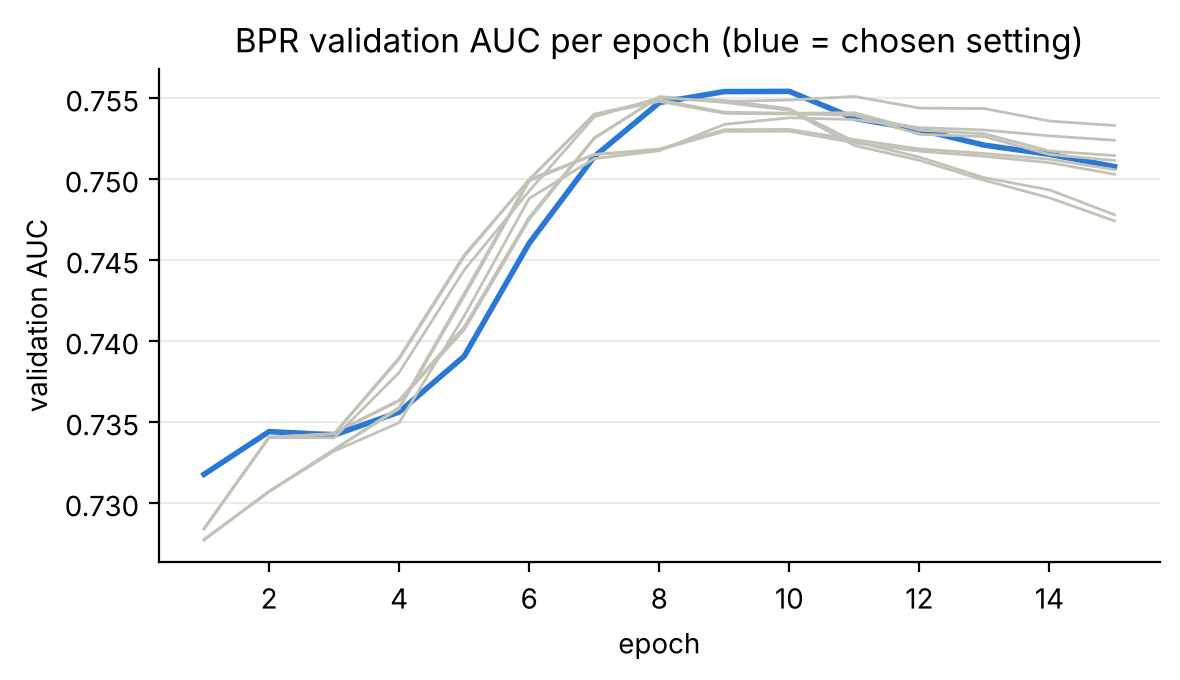

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for row in search:
    ax.plot(range(1, len(row["curve"]) + 1), row["curve"], lw=2 if (row["d"], row["lambda"]) == (best.d, best["lambda"]) else 1,
            color="#2a78d6" if (row["d"], row["lambda"]) == (best.d, best["lambda"]) else "#c3c2b7")
ax.set(title="BPR validation AUC per epoch (blue = chosen setting)", xlabel="epoch", ylabel="validation AUC")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#ecebe8")
plt.tight_layout(); plt.show()

In [9]:
cfg = dict(d=int(best.d), lam=float(best["lambda"]), epochs=int(best.best_epoch))
bpr_params = {}
for stage, s in STAGES.items():
    params, _ = train_bpr(s["fit"], **cfg)
    bpr_params[stage] = params
    summ[stage]["BPR"] = summarize(evaluate(bpr_scorer(params), s["ev"], s["neg"]))
results_table(summ["valid"], "AUC")

,all,0,1-5,>5
Random,0.506 ± 0.012,0.503 ± 0.031,0.504 ± 0.018,0.506 ± 0.015
Popularity,0.764 ± 0.015,0.047 ± 0.002,0.583 ± 0.014,0.969 ± 0.002
Item-Jaccard,0.714 ± 0.012,0.283 ± 0.012,0.567 ± 0.017,0.849 ± 0.009
Content (TF-IDF),0.641 ± 0.012,0.536 ± 0.033,0.597 ± 0.021,0.677 ± 0.014
BPR,0.769 ± 0.015,0.104 ± 0.011,0.589 ± 0.016,0.965 ± 0.003


### Why BPR struggles with rarely reviewed recipes

Negatives are sampled uniformly from the whole catalog, so a recipe with few reviews is drawn as a **negative** about as often as a
popular recipe but is almost never a **positive**. Every negative draw pushes its bias $\beta_i$ down. The table shows the effect
in the model trained for the test stage: the fewer training reviews, the lower the learned bias.

In [10]:
gu, gi, bi = bpr_params["test"]
counts = np.bincount(trainvalid.i.values, minlength=N_ITEMS)
grp = pd.cut(counts, [-1, 0, 5, 50, np.inf], labels=["0", "1-5", "6-50", ">50"])
pd.DataFrame({"training reviews": grp, "beta_i": bi, "|gamma_i|": np.linalg.norm(gi, axis=1)}) \
  .groupby("training reviews", observed=True).agg(recipes=("beta_i", "size"), mean_beta=("beta_i", "mean"),
                                                   mean_gamma_norm=("|gamma_i|", "mean")).round(3)

,recipes,mean_beta,mean_gamma_norm
training reviews,,,
0,22242,-0.508,0.110
1-5,176743,-0.133,0.285
6-50,31319,0.964,0.448
>50,1333,3.166,0.455


## 6. Results on the test split

In [11]:
for metric in ["AUC", "Hit@10", "NDCG@10"]:
    print(f"\n=== {metric} (test; mean ± 95% CI half-width over users) ===")
    print(results_table(summ["test"], metric).to_string())
n_users = {b: summ["test"]["BPR"][(b, "AUC")][2] for b in BUCKETS}
print("\nusers per bucket:", n_users)


=== AUC (test; mean ± 95% CI half-width over users) ===
                            all              0            1-5             >5
Random            0.505 ± 0.011  0.500 ± 0.026  0.516 ± 0.018  0.499 ± 0.014
Popularity        0.769 ± 0.013  0.048 ± 0.001  0.590 ± 0.013  0.969 ± 0.002
Item-Jaccard      0.712 ± 0.011  0.279 ± 0.010  0.546 ± 0.014  0.852 ± 0.008
Content (TF-IDF)  0.648 ± 0.012  0.538 ± 0.024  0.602 ± 0.018  0.686 ± 0.012
BPR               0.775 ± 0.014  0.098 ± 0.008  0.600 ± 0.015  0.966 ± 0.003

=== Hit@10 (test; mean ± 95% CI half-width over users) ===
                            all              0            1-5             >5
Random            0.106 ± 0.013  0.086 ± 0.023  0.106 ± 0.021  0.110 ± 0.014
Popularity        0.568 ± 0.019  0.000 ± 0.000  0.007 ± 0.005  0.901 ± 0.013
Item-Jaccard      0.374 ± 0.019  0.003 ± 0.005  0.111 ± 0.018  0.539 ± 0.022
Content (TF-IDF)  0.248 ± 0.018  0.140 ± 0.029  0.189 ± 0.024  0.289 ± 0.022
BPR               0.575 ± 0.019  0.0

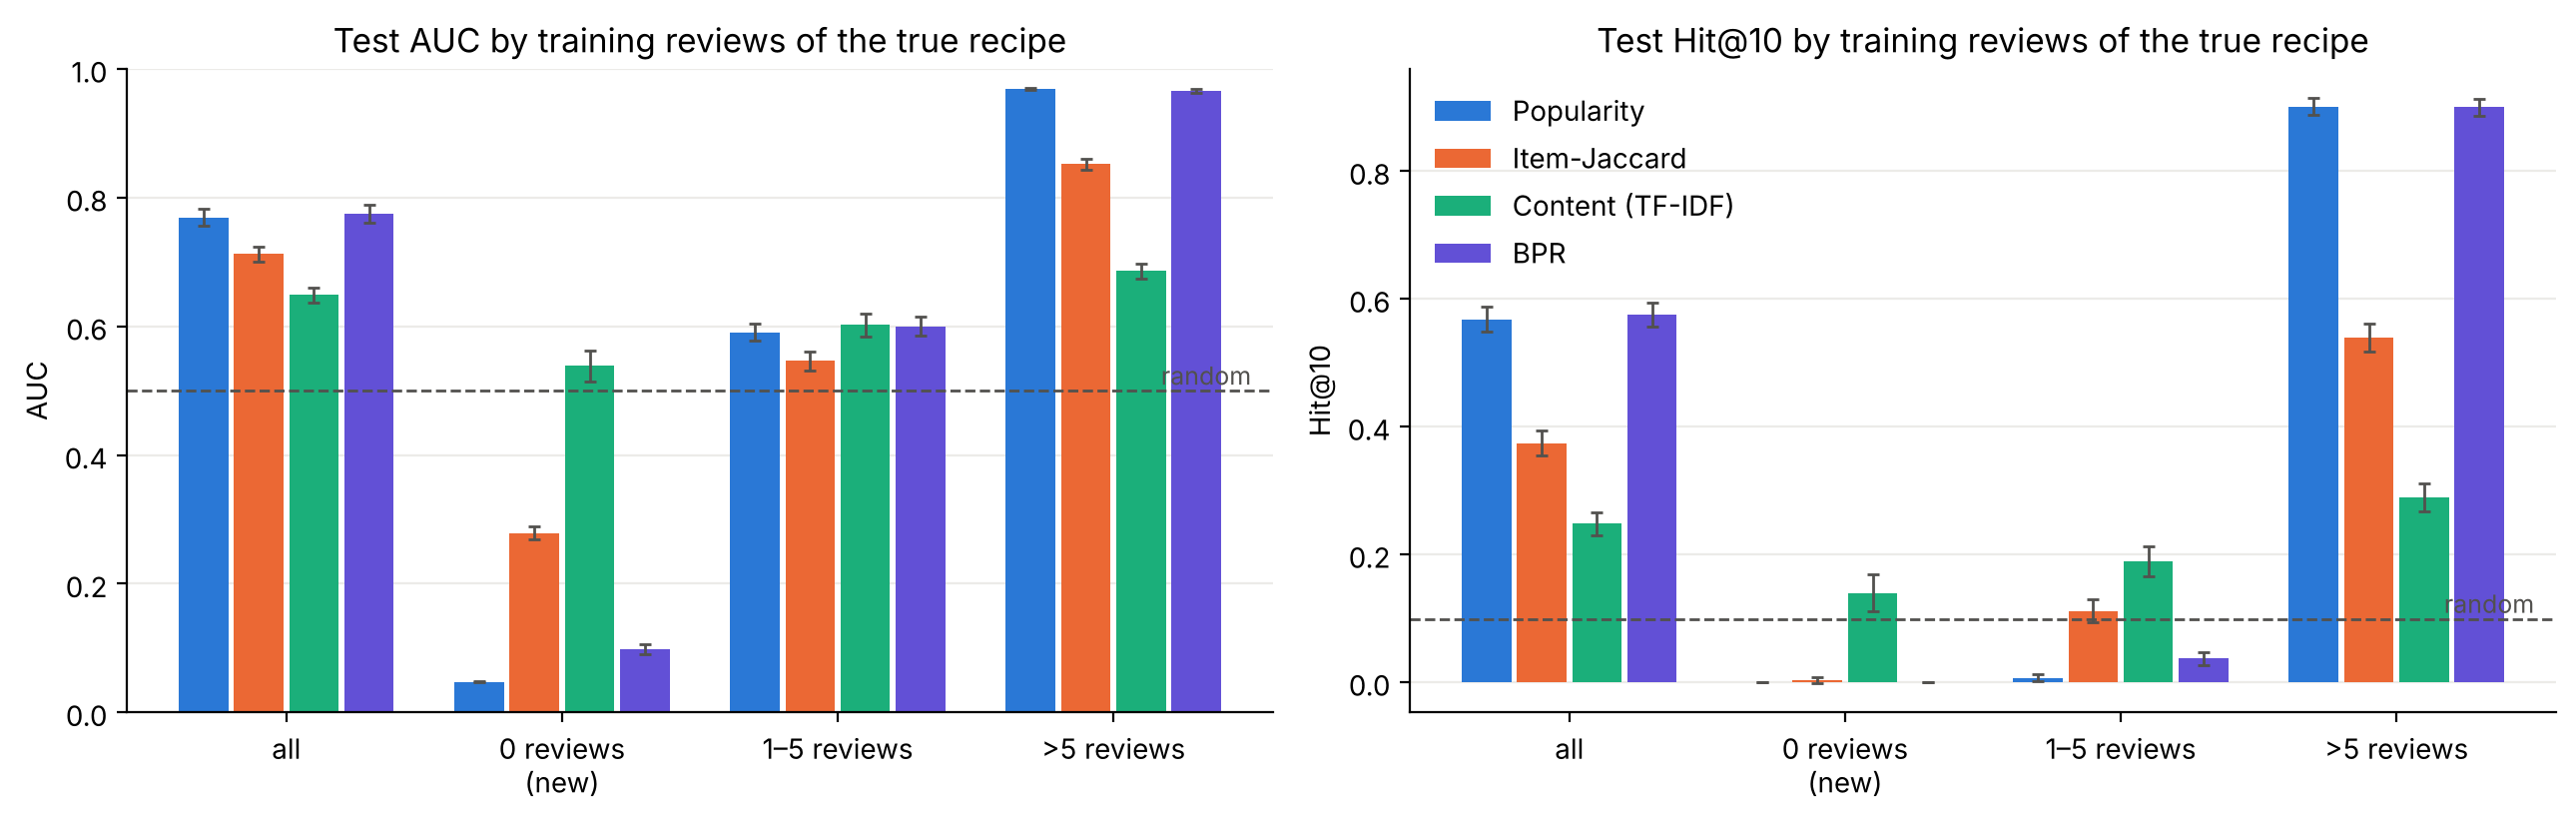

In [12]:
MODELS = ["Popularity", "Item-Jaccard", "Content (TF-IDF)", "BPR"]
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]   # categorical slots, fixed order
CHANCE = {"AUC": 0.5, "Hit@10": 10 / 101}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(BUCKETS))
w = 0.2
for ax, metric in zip(axes, ["AUC", "Hit@10"]):
    for k, (m, c) in enumerate(zip(MODELS, COLORS)):
        vals = [summ["test"][m][(b, metric)][0] for b in BUCKETS]
        errs = [summ["test"][m][(b, metric)][1] for b in BUCKETS]
        ax.bar(x + (k - 1.5) * w, vals, w * 0.9, yerr=errs, color=c, label=m,
               error_kw=dict(ecolor="#52514e", lw=1, capsize=2))
    ax.axhline(CHANCE[metric], color="#52514e", ls="--", lw=1)
    ax.text(len(BUCKETS) - 0.5, CHANCE[metric], " random", va="bottom", ha="right", color="#52514e", fontsize=9)
    ax.set_xticks(x, ["all", "0 reviews\n(new)", "1–5 reviews", ">5 reviews"])
    ax.set(title=f"Test {metric} by training reviews of the true recipe", ylabel=metric)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#ecebe8"); ax.set_axisbelow(True)
axes[0].set_ylim(0, 1)
axes[1].legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

## 7. Takeaways (test split)

- **Popularity and BPR are nearly identical.** BPR's overall AUC (0.775) is barely above popularity (0.769), and the two match on
  well-reviewed recipes (AUC ≈ 0.97, Hit@10 ≈ 0.90). Most of what BPR learns here is its item bias β_i, i.e. popularity. With data this
  sparse (density ≈ 1.8e-4), the user–item term adds little.
- **Collaborative models rank new recipes far below random.** On the 0-review bucket, popularity gets AUC 0.05 and BPR 0.10, and
  Hit@10 is 0 for both. A new recipe has zero counts (popularity) or a strongly negative β_i (BPR, see the table in section 5), while most
  sampled negatives have at least one review, so the true recipe lands at the bottom. Item-to-item Jaccard (0.28) suffers the same way.
- **Content-only is the only baseline above chance on new recipes** (AUC 0.54, Hit@10 0.14 vs 0.10 for random), but it is far worse
  on well-reviewed recipes (0.69 vs 0.97) because it ignores popularity and other users entirely.
- **Rare recipes (1–5 reviews) are hard for everyone:** all models are around AUC 0.55–0.60.

**Caveat about the evaluation.** Negatives are sampled uniformly from published recipes, and most recipes are unpopular, so on the
`>5` bucket a well-reviewed true recipe is easy to separate from obscure negatives. That inflates popularity-driven models there.
The per-bucket breakdown makes this visible; a popularity-matched negative sample would be a useful robustness check.

**What this means for the proposed model.** BPR + content features has to keep BPR's strength on well-reviewed recipes and
beat content-only on new and rare ones. The β_i result suggests one design choice to test: for recipes with little history, replace or
complement β_i with a bias predicted from content (w · x_i), so new recipes are not automatically pushed to the bottom.


In [13]:
import pickle
with open(f"{P}/baseline_results.pkl", "wb") as f:
    pickle.dump({"summaries": summ, "bpr_config": cfg, "bpr_search": search_df}, f)
print("saved", f"{P}/baseline_results.pkl")

saved processed/baseline_results.pkl
